# Removed Nanopartcile layer

Using device: cuda
Starting multi-folder simulation batch for 4 directories...

--- Processing Folder: Malaria_npz ---
Found 1000 files. Saving output to: Malaria_RGB


Simulating Malaria_npz:   0%|          | 0/1000 [00:00<?, ?it/s]

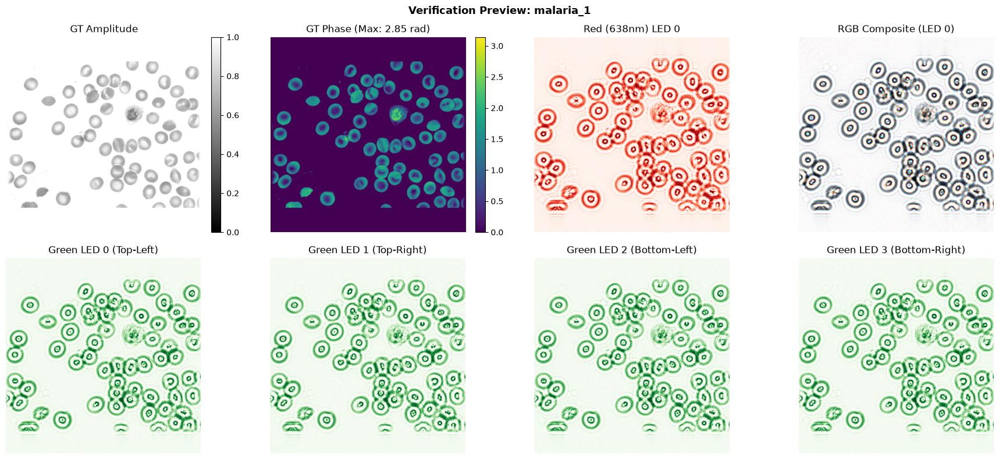

Simulating Malaria_npz: 100%|██████████| 1000/1000 [08:31<00:00,  1.95it/s]


Completed folder: /home/sakshi/Unet 3+ reconstruction/Malaria_RGB

--- Processing Folder: anemic_RBC_npz ---
Found 1000 files. Saving output to: Anemic_RGB


Simulating anemic_RBC_npz:   0%|          | 0/1000 [00:00<?, ?it/s]Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.1946511e-08..1.0].


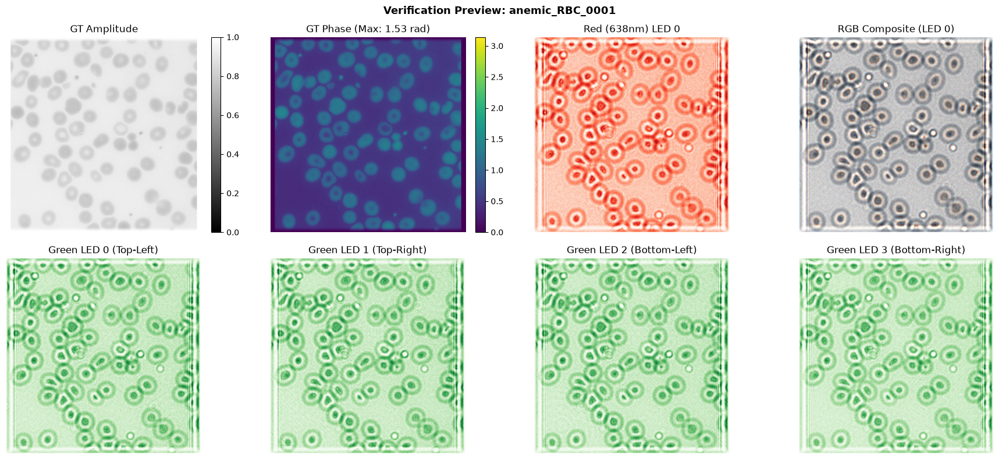

Simulating anemic_RBC_npz: 100%|██████████| 1000/1000 [09:21<00:00,  1.78it/s]


Completed folder: /home/sakshi/Unet 3+ reconstruction/Anemic_RGB

--- Processing Folder: rouleaux_npz ---
Found 1000 files. Saving output to: Rauleaux_RGB


Simulating rouleaux_npz:   0%|          | 0/1000 [00:00<?, ?it/s]Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.5737522e-10..1.0].


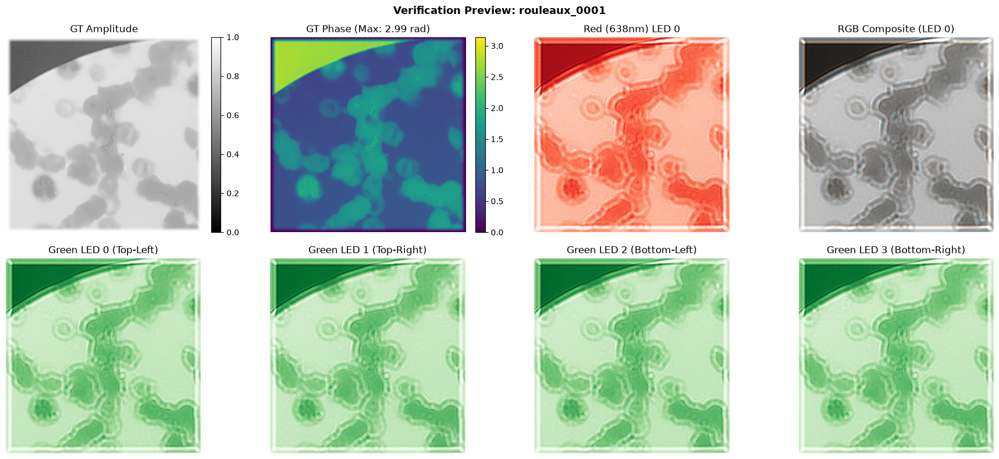

Simulating rouleaux_npz: 100%|██████████| 1000/1000 [09:20<00:00,  1.78it/s]


Completed folder: /home/sakshi/Unet 3+ reconstruction/Rauleaux_RGB

--- Processing Folder: Lung_cancer_npz ---
Found 1500 files. Saving output to: Lung_cancer_RGB


Simulating Lung_cancer_npz:   0%|          | 0/1500 [00:00<?, ?it/s]

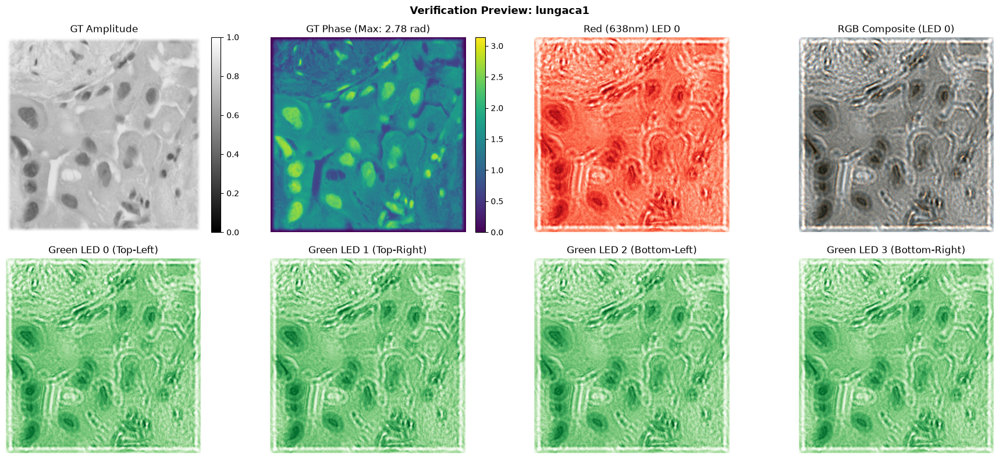

Simulating Lung_cancer_npz: 100%|██████████| 1500/1500 [14:04<00:00,  1.78it/s]

Completed folder: /home/sakshi/Unet 3+ reconstruction/Lung_cancer_RGB

All folders in batch successfully simulated and saved!


In [ ]:
import math
import os
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm

# ============================================================================
# Device Configuration
# ============================================================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True


# ============================================================================
# 1. Forward Model Classes (Single-Layer Direct Propagation)
# ============================================================================
class AngularSpectrumPropagator(nn.Module):
    def __init__(self, wavelength, pixel_size, z, shape):
        super().__init__()
        H, W = shape
        fx = torch.fft.fftfreq(W, d=pixel_size)
        fy = torch.fft.fftfreq(H, d=pixel_size)
        FX, FY = torch.meshgrid(fx, fy, indexing='xy')
        term = (1.0 / wavelength)**2 - FX**2 - FY**2
        mask = (term > 0).float()
        phase = 2 * math.pi * z * torch.sqrt(term * mask)
        H_tf = torch.polar(mask, phase)
        self.register_buffer('H', H_tf)

    def forward(self, u):
        U = torch.fft.fft2(u, dim=(-2, -1))
        U_prop = U * self.H.unsqueeze(0).unsqueeze(0)
        return torch.fft.ifft2(U_prop, dim=(-2, -1))


class LenslessMicroscope(nn.Module):
    def __init__(
        self,
        led_positions,
        wavelengths,
        sensor_pixel_size=1.55e-6,
        upsample_factor=2,
        z_total=500e-6,         # Sample to sensor distance (500 micrometers)
        sensor_shape=(512, 512),
        sim_canvas_dim=1024,
        add_noise=True,
        peak_photons=1e4,
        read_noise_std=0.01,
    ):
        super().__init__()
        self.led_positions = led_positions
        self.wavelengths = wavelengths
        self.upsample_factor = upsample_factor
        self.sensor_pixel_size = sensor_pixel_size
        self.optical_pixel_size = sensor_pixel_size / upsample_factor
        self.sensor_shape = sensor_shape
        self.sim_opt_shape = (
            sim_canvas_dim * upsample_factor,
            sim_canvas_dim * upsample_factor,
        )
        self.z_total = z_total
        self.add_noise = add_noise
        self.peak_photons = peak_photons
        self.read_noise_std = read_noise_std

        H_opt, W_opt = self.sim_opt_shape

        # Spatial Coordinates (Meters)
        x = torch.linspace(
            -W_opt / 2 * self.optical_pixel_size,
            W_opt / 2 * self.optical_pixel_size,
            W_opt,
            dtype=torch.float32,
        )
        y = torch.linspace(
            -H_opt / 2 * self.optical_pixel_size,
            H_opt / 2 * self.optical_pixel_size,
            H_opt,
            dtype=torch.float32,
        )
        X, Y = torch.meshgrid(x, y, indexing='xy')
        self.register_buffer('X_grid', X.unsqueeze(0).unsqueeze(0))
        self.register_buffer('Y_grid', Y.unsqueeze(0).unsqueeze(0))

        # Precomputed Transfer Functions for direct sample-to-sensor propagation
        self.prop_dict = nn.ModuleDict({
            ch: AngularSpectrumPropagator(
                wl, self.optical_pixel_size, self.z_total, self.sim_opt_shape
            )
            for ch, wl in wavelengths.items()
        })

    def forward(self, sensor_sample_field):
        H_s, W_s = self.sensor_shape
        H_c = self.sim_opt_shape[0] // self.upsample_factor
        W_c = self.sim_opt_shape[1] // self.upsample_factor

        pad_y = (H_c - H_s) // 2
        pad_x = (W_c - W_s) // 2

        # 1. Place stationary sample surrounded by unity background
        real_pad = F.pad(
            sensor_sample_field.real,
            (pad_x, pad_x, pad_y, pad_y),
            mode='constant',
            value=1.0,
        )
        imag_pad = F.pad(
            sensor_sample_field.imag,
            (pad_x, pad_x, pad_y, pad_y),
            mode='constant',
            value=0.0,
        )

        real_up = F.interpolate(
            real_pad,
            scale_factor=self.upsample_factor,
            mode='bilinear',
            align_corners=False,
        )
        imag_up = F.interpolate(
            imag_pad,
            scale_factor=self.upsample_factor,
            mode='bilinear',
            align_corners=False,
        )
        stationary_sample = torch.complex(real_up, imag_up)

        sensor_list = []

        for ch, wl in self.wavelengths.items():
            prop = self.prop_dict[ch]

            for xL, yL, zL in self.led_positions:
                # 2. Spherical Wavefront Illumination
                R = torch.sqrt(
                    (self.X_grid - xL)**2 + (self.Y_grid - yL)**2 + zL**2
                )
                inc_field = (1.0 / R) * torch.exp(1j * (2 * math.pi / wl) * R)
                inc_field = inc_field / inc_field.abs().mean()

                # Step 1: Illumination strikes specimen
                field = stationary_sample * inc_field

                # Step 2: Direct propagation from Sample -> Sensor
                sensor_field = prop(field)
                high_res_intensity = (sensor_field.abs() ** 2).squeeze(1)

                # Step 3: Binning back to physical sensor pixel pitch
                canvas_intensity = F.avg_pool2d(
                    high_res_intensity.unsqueeze(1),
                    kernel_size=self.upsample_factor,
                    stride=self.upsample_factor,
                ).squeeze(1)

                # Step 4: Corrected Geometric Projection Offset with Strict Bounds Clamping
                proj_x = -xL * (self.z_total / zL)
                proj_y = -yL * (self.z_total / zL)

                shift_x = int(round(proj_x / self.sensor_pixel_size))
                shift_y = int(round(proj_y / self.sensor_pixel_size))

                y_start = pad_y + shift_y
                x_start = pad_x + shift_x

                h_canvas, w_canvas = canvas_intensity.shape[-2], canvas_intensity.shape[-1]
                y_start = max(0, min(y_start, h_canvas - H_s))
                x_start = max(0, min(x_start, w_canvas - W_s))

                sensor_intensity = canvas_intensity[
                    ..., y_start : y_start + H_s, x_start : x_start + W_s
                ]

                # Safety fallback to guarantee exact (512, 512) shape
                if sensor_intensity.shape[-2] != H_s or sensor_intensity.shape[-1] != W_s:
                    sensor_intensity = F.interpolate(
                        sensor_intensity.unsqueeze(1), size=(H_s, W_s), mode='bilinear', align_corners=False
                    ).squeeze(1)

                # Step 5: Noise modeling
                if self.add_noise:
                    scaled = sensor_intensity * self.peak_photons
                    noisy = torch.poisson(torch.clamp(scaled, min=0.0)) / self.peak_photons
                    sensor_intensity = torch.clamp(
                        noisy + torch.randn_like(noisy) * self.read_noise_std, 0.0, 1.0
                    )

                sensor_list.append(sensor_intensity)

        return torch.stack(sensor_list, dim=1)


# ============================================================================
# 2. Hardware Utilities
# ============================================================================
def build_led_positions(
    pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=0.10
):
    """distance_z=0.10 sets the light-to-sample distance to 10 cm."""
    positions = []
    start_x = -(n_led_x - 1) * pitch_x / 2.0
    start_y = -(n_led_y - 1) * pitch_y / 2.0
    for i in range(n_led_x):
        for j in range(n_led_y):
            positions.append(
                (start_x + i * pitch_x, start_y + j * pitch_y, distance_z)
            )
    return positions


# ============================================================================
# 3. Visualization Helper
# ============================================================================
def plot_sample_verification(base_name, amp, phase, sensor_np):
    """Plots a complete visual check of the simulated sample for a 2x2 LED grid."""
    r_center = sensor_np[0]
    g_center = sensor_np[4 + 0]
    b_center = sensor_np[8 + 0]

    r_norm = cv2.normalize(r_center, None, 0, 1, cv2.NORM_MINMAX)
    g_norm = cv2.normalize(g_center, None, 0, 1, cv2.NORM_MINMAX)
    b_norm = cv2.normalize(b_center, None, 0, 1, cv2.NORM_MINMAX)
    rgb_composite = np.stack([r_norm, g_norm, b_norm], axis=-1)

    fig = plt.figure(figsize=(18, 8))
    fig.suptitle(f"Verification Preview: {base_name}", fontsize=13, fontweight='bold')

    ax0 = plt.subplot2grid((2, 4), (0, 0))
    ax1 = plt.subplot2grid((2, 4), (0, 1))
    ax2 = plt.subplot2grid((2, 4), (0, 2))
    ax3 = plt.subplot2grid((2, 4), (0, 3))

    im0 = ax0.imshow(amp, cmap="gray", vmin=0, vmax=1)
    ax0.set_title("GT Amplitude")
    ax0.axis("off")
    fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)

    im1 = ax1.imshow(phase, cmap="viridis", vmin=0, vmax=np.pi)
    ax1.set_title(f"GT Phase (Max: {phase.max():.2f} rad)")
    ax1.axis("off")
    fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

    ax2.imshow(r_center, cmap="Reds_r")
    ax2.set_title("Red (638nm) LED 0")
    ax2.axis("off")

    ax3.imshow(rgb_composite)
    ax3.set_title("RGB Composite (LED 0)")
    ax3.axis("off")

    ax4 = plt.subplot2grid((2, 4), (1, 0))
    ax5 = plt.subplot2grid((2, 4), (1, 1))
    ax6 = plt.subplot2grid((2, 4), (1, 2))
    ax7 = plt.subplot2grid((2, 4), (1, 3))

    ax4.imshow(sensor_np[4 + 0], cmap="Greens_r")
    ax4.set_title("Green LED 0 (Top-Left)")
    ax4.axis("off")

    ax5.imshow(sensor_np[4 + 1], cmap="Greens_r")
    ax5.set_title("Green LED 1 (Top-Right)")
    ax5.axis("off")

    ax6.imshow(sensor_np[4 + 2], cmap="Greens_r")
    ax6.set_title("Green LED 2 (Bottom-Left)")
    ax6.axis("off")

    ax7.imshow(sensor_np[4 + 3], cmap="Greens_r")
    ax7.set_title("Green LED 3 (Bottom-Right)")
    ax7.axis("off")

    plt.tight_layout()
    plt.show()


# ============================================================================
# 4. Single & Multi-Folder Execution Functions
# ============================================================================
def simulate_single_folder(
    input_folder_path,
    output_folder_path,
    num_samples_to_visualize=1,
    sensor_pixel_size=1.55e-6,
    upsample_factor=2,
    sample_to_sensor_z=500e-6,  # 500 micrometers
    light_to_sample_z=0.10,     # 10 cm
    target_dim=512,
    sim_canvas_dim=1024,
    add_noise=True,
):
    in_path = Path(input_folder_path)
    out_path = Path(output_folder_path)
    out_path.mkdir(parents=True, exist_ok=True)

    npz_files = sorted(in_path.glob("*.npz"))
    npy_phase_files = sorted(in_path.glob("*_phase.npy"))

    if npz_files:
        file_list = npz_files
        is_npz = True
    elif npy_phase_files:
        file_list = npy_phase_files
        is_npz = False
    else:
        print(f"Error: No .npz or .npy optical files found in {in_path}")
        return

    print(f"\n--- Processing Folder: {in_path.name} ---")
    print(f"Found {len(file_list)} files. Saving output to: {out_path}")

    led_positions = build_led_positions(pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=light_to_sample_z)
    wavelengths = {'R': 638e-9, 'G': 532e-9, 'B': 450e-9}
    sensor_shape = (target_dim, target_dim)

    model = LenslessMicroscope(
        led_positions=led_positions,
        wavelengths=wavelengths,
        sensor_pixel_size=sensor_pixel_size,
        upsample_factor=upsample_factor,
        z_total=sample_to_sensor_z,
        sensor_shape=sensor_shape,
        sim_canvas_dim=sim_canvas_dim,
        add_noise=add_noise,
    ).to(device).eval()

    for idx, file_path in enumerate(tqdm(file_list, desc=f"Simulating {in_path.name}")):
        if is_npz:
            base_name = file_path.stem
            with np.load(file_path) as data:
                amplitude = data['amplitude'].astype(np.float32)
                phase = data['phase'].astype(np.float32)
        else:
            base_name = file_path.stem.replace("_phase", "")
            amp_path = file_path.parent / f"{base_name}_amp.npy"
            if not amp_path.exists():
                continue
            phase = np.load(file_path).astype(np.float32)
            amplitude = np.load(amp_path).astype(np.float32)

        if amplitude.shape != sensor_shape:
            amplitude = cv2.resize(amplitude, sensor_shape, interpolation=cv2.INTER_LINEAR)
            phase = cv2.resize(phase, sensor_shape, interpolation=cv2.INTER_LINEAR)

        complex_sample = amplitude * np.exp(1j * phase)
        complex_tensor = torch.tensor(complex_sample, dtype=torch.complex64).unsqueeze(0).unsqueeze(0).to(device)

        with torch.no_grad():
            sensor_tensor = model(complex_tensor)

        sensor_np = sensor_tensor.squeeze(0).cpu().numpy().astype(np.float32)

        save_file = out_path / f"{base_name}_data.npz"
        np.savez_compressed(
            save_file,
            input_tensor=sensor_np,
            target_phase=phase,
            target_amp=amplitude
        )

        if idx < num_samples_to_visualize:
            plot_sample_verification(base_name, amplitude, phase, sensor_np)

    print(f"Completed folder: {out_path.resolve()}")


def simulate_multiple_folders(folder_pairs, **kwargs):
    """
    Processes multiple input/output folder pairs sequentially in a single run.
    folder_pairs: list of tuples -> [(input_dir_1, output_dir_1), (input_dir_2, output_dir_2), ...]
    """
    print(f"Starting multi-folder simulation batch for {len(folder_pairs)} directories...")
    for in_dir, out_dir in folder_pairs:
        simulate_single_folder(
            input_folder_path=in_dir,
            output_folder_path=out_dir,
            **kwargs
        )
    print("\nAll folders in batch successfully simulated and saved!")


# ============================================================================
# 5. Execution Block (Multi-Folder Support)
# ============================================================================
if __name__ == "__main__":
    

    # Define multiple input and output folder pairs here
    dataset_pairs = [
        (
            os.path.join("/home/sakshi/Unet 3+ reconstruction/Dataset_processed/Testing_ground_truth/extracted_images"),
            "./Extracted_Images"
        ),
        (
            os.path.join("/home/sakshi/Unet 3+ reconstruction/Dataset_processed/Testing_ground_truth/NILM"),
            "./NILM"
        )
        # Add additional folders here as needed:
        # (os.path.join(base_dir, "Dataset_processed/Testing_ground_truth/another_folder"), "./Another_RGB")
    ]

    simulate_multiple_folders(
        folder_pairs=dataset_pairs,
        num_samples_to_visualize=1,
        sensor_pixel_size=1.55e-6,
        upsample_factor=2,
        sample_to_sensor_z=500e-6,  # 500 micrometers sample-to-sensor
        light_to_sample_z=0.10,     # 10 cm light-to-sample
        target_dim=512,
        sim_canvas_dim=1024,
        add_noise=True
    )

In [2]:
import math
import os
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm import tqdm

Using device: cuda
Starting multi-folder simulation batch for 1 directories...

--- Processing Folder: healthy_RBC_npz ---
Found 1000 files. Saving output to: Healthy_Images


Simulating healthy_RBC_npz:   0%|          | 0/1000 [00:00<?, ?it/s]Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.4111394e-08..1.0].


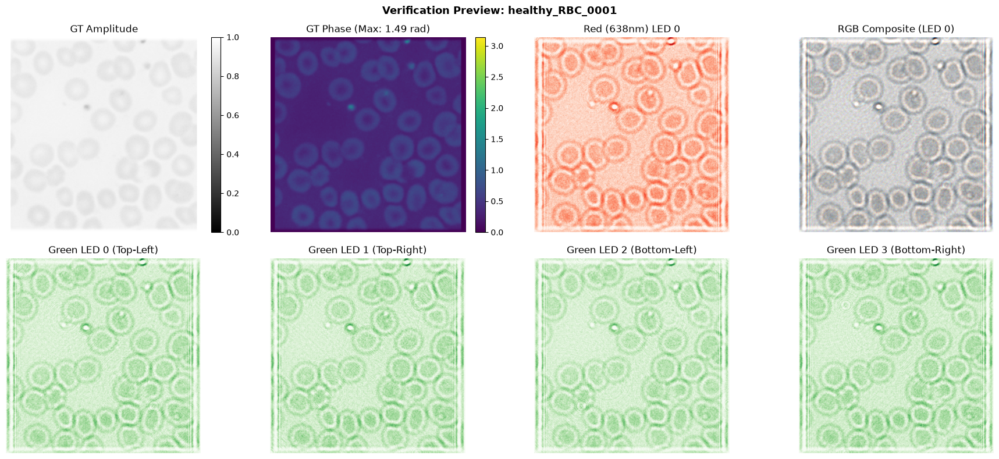

Simulating healthy_RBC_npz:  29%|██▉       | 294/1000 [04:39<11:10,  1.05it/s]


KeyboardInterrupt: 

In [3]:
# ============================================================================
# Device Configuration
# ============================================================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True


# ============================================================================
# 1. Forward Model Classes (Single-Layer Direct Propagation)
# ============================================================================
class AngularSpectrumPropagator(nn.Module):
    def __init__(self, wavelength, pixel_size, z, shape):
        super().__init__()
        H, W = shape
        fx = torch.fft.fftfreq(W, d=pixel_size)
        fy = torch.fft.fftfreq(H, d=pixel_size)
        FX, FY = torch.meshgrid(fx, fy, indexing='xy')
        term = (1.0 / wavelength)**2 - FX**2 - FY**2
        mask = (term > 0).float()
        phase = 2 * math.pi * z * torch.sqrt(term * mask)
        H_tf = torch.polar(mask, phase)
        self.register_buffer('H', H_tf)

    def forward(self, u):
        U = torch.fft.fft2(u, dim=(-2, -1))
        U_prop = U * self.H.unsqueeze(0).unsqueeze(0)
        return torch.fft.ifft2(U_prop, dim=(-2, -1))


class LenslessMicroscope(nn.Module):
    def __init__(
        self,
        led_positions,
        wavelengths,
        sensor_pixel_size=1.55e-6,
        upsample_factor=2,
        z_total=500e-6,         # Sample to sensor distance (500 micrometers)
        sensor_shape=(512, 512),
        sim_canvas_dim=1024,
        add_noise=True,
        peak_photons=1e4,
        read_noise_std=0.01,
    ):
        super().__init__()
        self.led_positions = led_positions
        self.wavelengths = wavelengths
        self.upsample_factor = upsample_factor
        self.sensor_pixel_size = sensor_pixel_size
        self.optical_pixel_size = sensor_pixel_size / upsample_factor
        self.sensor_shape = sensor_shape
        self.sim_opt_shape = (
            sim_canvas_dim * upsample_factor,
            sim_canvas_dim * upsample_factor,
        )
        self.z_total = z_total
        self.add_noise = add_noise
        self.peak_photons = peak_photons
        self.read_noise_std = read_noise_std

        H_opt, W_opt = self.sim_opt_shape

        # Spatial Coordinates (Meters)
        x = torch.linspace(
            -W_opt / 2 * self.optical_pixel_size,
            W_opt / 2 * self.optical_pixel_size,
            W_opt,
            dtype=torch.float32,
        )
        y = torch.linspace(
            -H_opt / 2 * self.optical_pixel_size,
            H_opt / 2 * self.optical_pixel_size,
            H_opt,
            dtype=torch.float32,
        )
        X, Y = torch.meshgrid(x, y, indexing='xy')
        self.register_buffer('X_grid', X.unsqueeze(0).unsqueeze(0))
        self.register_buffer('Y_grid', Y.unsqueeze(0).unsqueeze(0))

        # Precomputed Transfer Functions for direct sample-to-sensor propagation
        self.prop_dict = nn.ModuleDict({
            ch: AngularSpectrumPropagator(
                wl, self.optical_pixel_size, self.z_total, self.sim_opt_shape
            )
            for ch, wl in wavelengths.items()
        })

    def forward(self, sensor_sample_field):
        H_s, W_s = self.sensor_shape
        H_c = self.sim_opt_shape[0] // self.upsample_factor
        W_c = self.sim_opt_shape[1] // self.upsample_factor

        pad_y = (H_c - H_s) // 2
        pad_x = (W_c - W_s) // 2

        # 1. Place stationary sample surrounded by unity background
        real_pad = F.pad(
            sensor_sample_field.real,
            (pad_x, pad_x, pad_y, pad_y),
            mode='constant',
            value=1.0,
        )
        imag_pad = F.pad(
            sensor_sample_field.imag,
            (pad_x, pad_x, pad_y, pad_y),
            mode='constant',
            value=0.0,
        )

        real_up = F.interpolate(
            real_pad,
            scale_factor=self.upsample_factor,
            mode='bilinear',
            align_corners=False,
        )
        imag_up = F.interpolate(
            imag_pad,
            scale_factor=self.upsample_factor,
            mode='bilinear',
            align_corners=False,
        )
        stationary_sample = torch.complex(real_up, imag_up)

        sensor_list = []

        for ch, wl in self.wavelengths.items():
            prop = self.prop_dict[ch]

            for xL, yL, zL in self.led_positions:
                # 2. Spherical Wavefront Illumination
                R = torch.sqrt(
                    (self.X_grid - xL)**2 + (self.Y_grid - yL)**2 + zL**2
                )
                inc_field = (1.0 / R) * torch.exp(1j * (2 * math.pi / wl) * R)
                inc_field = inc_field / inc_field.abs().mean()

                # Step 1: Illumination strikes specimen
                field = stationary_sample * inc_field

                # Step 2: Direct propagation from Sample -> Sensor
                sensor_field = prop(field)
                high_res_intensity = (sensor_field.abs() ** 2).squeeze(1)

                # Step 3: Binning back to physical sensor pixel pitch
                canvas_intensity = F.avg_pool2d(
                    high_res_intensity.unsqueeze(1),
                    kernel_size=self.upsample_factor,
                    stride=self.upsample_factor,
                ).squeeze(1)

                # Step 4: Corrected Geometric Projection Offset with Strict Bounds Clamping
                proj_x = -xL * (self.z_total / zL)
                proj_y = -yL * (self.z_total / zL)

                shift_x = int(round(proj_x / self.sensor_pixel_size))
                shift_y = int(round(proj_y / self.sensor_pixel_size))

                y_start = pad_y + shift_y
                x_start = pad_x + shift_x

                h_canvas, w_canvas = canvas_intensity.shape[-2], canvas_intensity.shape[-1]
                y_start = max(0, min(y_start, h_canvas - H_s))
                x_start = max(0, min(x_start, w_canvas - W_s))

                sensor_intensity = canvas_intensity[
                    ..., y_start : y_start + H_s, x_start : x_start + W_s
                ]

                # Safety fallback to guarantee exact (512, 512) shape
                if sensor_intensity.shape[-2] != H_s or sensor_intensity.shape[-1] != W_s:
                    sensor_intensity = F.interpolate(
                        sensor_intensity.unsqueeze(1), size=(H_s, W_s), mode='bilinear', align_corners=False
                    ).squeeze(1)

                # Step 5: Noise modeling
                if self.add_noise:
                    scaled = sensor_intensity * self.peak_photons
                    noisy = torch.poisson(torch.clamp(scaled, min=0.0)) / self.peak_photons
                    sensor_intensity = torch.clamp(
                        noisy + torch.randn_like(noisy) * self.read_noise_std, 0.0, 1.0
                    )

                sensor_list.append(sensor_intensity)

        return torch.stack(sensor_list, dim=1)


# ============================================================================
# 2. Hardware Utilities
# ============================================================================
def build_led_positions(
    pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=0.10
):
    """distance_z=0.10 sets the light-to-sample distance to 10 cm."""
    positions = []
    start_x = -(n_led_x - 1) * pitch_x / 2.0
    start_y = -(n_led_y - 1) * pitch_y / 2.0
    for i in range(n_led_x):
        for j in range(n_led_y):
            positions.append(
                (start_x + i * pitch_x, start_y + j * pitch_y, distance_z)
            )
    return positions


# ============================================================================
# 3. Visualization Helper
# ============================================================================
def plot_sample_verification(base_name, amp, phase, sensor_np):
    """Plots a complete visual check of the simulated sample for a 2x2 LED grid."""
    r_center = sensor_np[0]
    g_center = sensor_np[4 + 0]
    b_center = sensor_np[8 + 0]

    r_norm = cv2.normalize(r_center, None, 0, 1, cv2.NORM_MINMAX)
    g_norm = cv2.normalize(g_center, None, 0, 1, cv2.NORM_MINMAX)
    b_norm = cv2.normalize(b_center, None, 0, 1, cv2.NORM_MINMAX)
    rgb_composite = np.stack([r_norm, g_norm, b_norm], axis=-1)

    fig = plt.figure(figsize=(18, 8))
    fig.suptitle(f"Verification Preview: {base_name}", fontsize=13, fontweight='bold')

    ax0 = plt.subplot2grid((2, 4), (0, 0))
    ax1 = plt.subplot2grid((2, 4), (0, 1))
    ax2 = plt.subplot2grid((2, 4), (0, 2))
    ax3 = plt.subplot2grid((2, 4), (0, 3))

    im0 = ax0.imshow(amp, cmap="gray", vmin=0, vmax=1)
    ax0.set_title("GT Amplitude")
    ax0.axis("off")
    fig.colorbar(im0, ax=ax0, fraction=0.046, pad=0.04)

    im1 = ax1.imshow(phase, cmap="viridis", vmin=0, vmax=np.pi)
    ax1.set_title(f"GT Phase (Max: {phase.max():.2f} rad)")
    ax1.axis("off")
    fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

    ax2.imshow(r_center, cmap="Reds_r")
    ax2.set_title("Red (638nm) LED 0")
    ax2.axis("off")

    ax3.imshow(rgb_composite)
    ax3.set_title("RGB Composite (LED 0)")
    ax3.axis("off")

    ax4 = plt.subplot2grid((2, 4), (1, 0))
    ax5 = plt.subplot2grid((2, 4), (1, 1))
    ax6 = plt.subplot2grid((2, 4), (1, 2))
    ax7 = plt.subplot2grid((2, 4), (1, 3))

    ax4.imshow(sensor_np[4 + 0], cmap="Greens_r")
    ax4.set_title("Green LED 0 (Top-Left)")
    ax4.axis("off")

    ax5.imshow(sensor_np[4 + 1], cmap="Greens_r")
    ax5.set_title("Green LED 1 (Top-Right)")
    ax5.axis("off")

    ax6.imshow(sensor_np[4 + 2], cmap="Greens_r")
    ax6.set_title("Green LED 2 (Bottom-Left)")
    ax6.axis("off")

    ax7.imshow(sensor_np[4 + 3], cmap="Greens_r")
    ax7.set_title("Green LED 3 (Bottom-Right)")
    ax7.axis("off")

    plt.tight_layout()
    plt.show()


# ============================================================================
# 4. Single & Multi-Folder Execution Functions
# ============================================================================
def simulate_single_folder(
    input_folder_path,
    output_folder_path,
    num_samples_to_visualize=1,
    sensor_pixel_size=1.55e-6,
    upsample_factor=2,
    sample_to_sensor_z=500e-6,  # 500 micrometers
    light_to_sample_z=0.10,     # 10 cm
    target_dim=512,
    sim_canvas_dim=1024,
    add_noise=True,
):
    in_path = Path(input_folder_path)
    out_path = Path(output_folder_path)
    out_path.mkdir(parents=True, exist_ok=True)

    npz_files = sorted(in_path.glob("*.npz"))
    npy_phase_files = sorted(in_path.glob("*_phase.npy"))

    if npz_files:
        file_list = npz_files
        is_npz = True
    elif npy_phase_files:
        file_list = npy_phase_files
        is_npz = False
    else:
        print(f"Error: No .npz or .npy optical files found in {in_path}")
        return

    print(f"\n--- Processing Folder: {in_path.name} ---")
    print(f"Found {len(file_list)} files. Saving output to: {out_path}")

    led_positions = build_led_positions(pitch_x=8e-3, pitch_y=8e-3, n_led_x=2, n_led_y=2, distance_z=light_to_sample_z)
    wavelengths = {'R': 638e-9, 'G': 532e-9, 'B': 450e-9}
    sensor_shape = (target_dim, target_dim)

    model = LenslessMicroscope(
        led_positions=led_positions,
        wavelengths=wavelengths,
        sensor_pixel_size=sensor_pixel_size,
        upsample_factor=upsample_factor,
        z_total=sample_to_sensor_z,
        sensor_shape=sensor_shape,
        sim_canvas_dim=sim_canvas_dim,
        add_noise=add_noise,
    ).to(device).eval()

    for idx, file_path in enumerate(tqdm(file_list, desc=f"Simulating {in_path.name}")):
        if is_npz:
            base_name = file_path.stem
            with np.load(file_path) as data:
                amplitude = data['amplitude'].astype(np.float32)
                phase = data['phase'].astype(np.float32)
        else:
            base_name = file_path.stem.replace("_phase", "")
            amp_path = file_path.parent / f"{base_name}_amp.npy"
            if not amp_path.exists():
                continue
            phase = np.load(file_path).astype(np.float32)
            amplitude = np.load(amp_path).astype(np.float32)

        if amplitude.shape != sensor_shape:
            amplitude = cv2.resize(amplitude, sensor_shape, interpolation=cv2.INTER_LINEAR)
            phase = cv2.resize(phase, sensor_shape, interpolation=cv2.INTER_LINEAR)

        complex_sample = amplitude * np.exp(1j * phase)
        complex_tensor = torch.tensor(complex_sample, dtype=torch.complex64).unsqueeze(0).unsqueeze(0).to(device)

        with torch.no_grad():
            sensor_tensor = model(complex_tensor)

        sensor_np = sensor_tensor.squeeze(0).cpu().numpy().astype(np.float32)

        save_file = out_path / f"{base_name}_data.npz"
        np.savez_compressed(
            save_file,
            input_tensor=sensor_np,
            target_phase=phase,
            target_amp=amplitude
        )

        if idx < num_samples_to_visualize:
            plot_sample_verification(base_name, amplitude, phase, sensor_np)

    print(f"Completed folder: {out_path.resolve()}")


def simulate_multiple_folders(folder_pairs, **kwargs):
    """
    Processes multiple input/output folder pairs sequentially in a single run.
    folder_pairs: list of tuples -> [(input_dir_1, output_dir_1), (input_dir_2, output_dir_2), ...]
    """
    print(f"Starting multi-folder simulation batch for {len(folder_pairs)} directories...")
    for in_dir, out_dir in folder_pairs:
        simulate_single_folder(
            input_folder_path=in_dir,
            output_folder_path=out_dir,
            **kwargs
        )
    print("\nAll folders in batch successfully simulated and saved!")


# ============================================================================
# 5. Execution Block (Multi-Folder Support)
# ============================================================================
if __name__ == "__main__":
    

    # Define multiple input and output folder pairs here
    dataset_pairs = [
        (
            os.path.join("/home/sakshi/Unet 3+ reconstruction/Dataset_processed/healthy_RBC_npz"),
            "./Healthy_Images"
        )
        # Add additional folders here as needed:
        # (os.path.join(base_dir, "Dataset_processed/Testing_ground_truth/another_folder"), "./Another_RGB")
    ]

    simulate_multiple_folders(
        folder_pairs=dataset_pairs,
        num_samples_to_visualize=1,
        sensor_pixel_size=1.55e-6,
        upsample_factor=2,
        sample_to_sensor_z=500e-6,  # 500 micrometers sample-to-sensor
        light_to_sample_z=0.10,     # 10 cm light-to-sample
        target_dim=512,
        sim_canvas_dim=1024,
        add_noise=True
    )